# B08 怎样识别垃圾短信并分析误报？

使用本地真实 SMS Spam Collection 数据，去除重复文本，再比较多数类基线与 TF-IDF+朴素贝叶斯。垃圾短信召回和正常短信误报分别评价。

先修：B06—B07；稀疏表示、朴素贝叶斯与分类指标。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 读入真实文本并处理重复
同一短信的复制版本出现在训练和测试会虚高分数。先按原文检查冲突标签，再去重。只做保守空白清理，保留金额、链接等有用线索。

In [2]:
import pandas as pd, numpy as np, json
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
messages = pd.read_csv(COURSE_ROOT / 'assets/data/sms.tsv', sep='\t')
messages['text'] = messages['text'].fillna('').str.replace(r'\s+', ' ', regex=True).str.strip()
assert messages['label'].isin(['ham','spam']).all()
conflicts = messages.groupby('text')['label'].nunique()
messages = messages.loc[~messages['text'].isin(conflicts[conflicts > 1].index)]
messages = messages.loc[messages['text'].ne('')].drop_duplicates('text').reset_index(drop=True)
y = (messages['label'] == 'spam').astype(int)
train_idx, test_idx = train_test_split(np.arange(len(messages)), test_size=0.25, stratify=y, random_state=8)
assert set(messages.loc[train_idx,'text']).isdisjoint(set(messages.loc[test_idx,'text']))


## 2. 文本转换只学习训练集词表
TF-IDF 的每一列代表词，值表示词在某短信中的相对重要程度。Pipeline 保证测试文本不能影响词表与词频；稀疏矩阵无需展开成巨大的密集表。

In [3]:
model = make_pipeline(TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=2), MultinomialNB(alpha=0.5))
model.fit(messages.loc[train_idx,'text'], y.loc[train_idx])
print('词表大小', len(model.named_steps['tfidfvectorizer'].vocabulary_))
prediction = model.predict(messages.loc[test_idx,'text'])
probability = model.predict_proba(messages.loc[test_idx,'text'])[:,1]


词表大小 9282


## 3. 指标需要围绕误报与漏报
“全部正常”可能准确率很高，但垃圾召回为零。混淆矩阵的行是真实类别、列是预测类别；precision 回答拦截短信中多少真是垃圾，recall 回答垃圾短信中拦住多少。

In [4]:
truth = y.loc[test_idx].to_numpy()
def classification_scores(truth, pred):
    return {'accuracy': float(np.mean(truth == pred)), 'precision': float(precision_score(truth,pred,zero_division=0)), 'recall': float(recall_score(truth,pred,zero_division=0)), 'f1': float(f1_score(truth,pred,zero_division=0))}
metrics = {'rows_after_deduplication': len(messages), 'baseline': classification_scores(truth,np.zeros_like(truth)), 'tfidf_nb': classification_scores(truth,prediction)}
matrix = confusion_matrix(truth, prediction, labels=[0,1])


## 4. 保存错误样例与矩阵
错误列表用于理解，而不是回看测试集后不断修改模型。若要调阈值或平滑参数，应另留验证集。数据含真实短信文本，只在本地教学使用。

In [5]:
result = messages.loc[test_idx].copy(); result['prediction'] = prediction; result['spam_probability'] = probability
result.to_csv(OUT_DIR / 'predictions.csv', index=False, encoding='utf-8-sig')
result.loc[truth != prediction].to_csv(OUT_DIR / 'errors.csv', index=False, encoding='utf-8-sig')
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
plt.imshow(matrix, cmap='Blues'); plt.xticks([0,1],['正常','垃圾']); plt.yticks([0,1],['正常','垃圾'])
for i in range(2):
    for j in range(2): plt.text(j,i,str(matrix[i,j]),ha='center',va='center')
plt.xlabel('预测'); plt.ylabel('真实'); plt.tight_layout(); plt.savefig(OUT_DIR / 'confusion.png'); plt.close(); print(metrics)


{'rows_after_deduplication': 5158, 'baseline': {'accuracy': 0.8751937984496124, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}, 'tfidf_nb': {'accuracy': 0.9751937984496124, 'precision': 1.0, 'recall': 0.8012422360248447, 'f1': 0.8896551724137931}}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

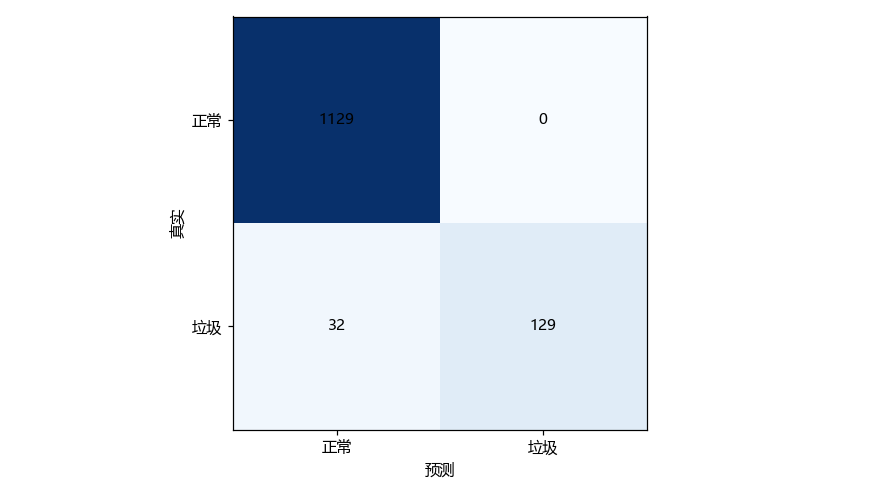

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
英文旧短信数据不能代表当前中文诈骗；真实部署前需要新数据评估与误报处理。此例未把概率作严格校准概率使用。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。